In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from sqlalchemy import create_engine, text
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.dpi":        150,
    "figure.figsize":    (12, 5),
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "axes.titlesize":    14,
    "axes.titleweight":  "bold",
    "font.family":       "sans-serif",
})

DB_PATH = r"D:\customer_intelligence_platform\data\processed\olist.db"
engine  = create_engine(f"sqlite:///{DB_PATH}")

def sql(query):
    with engine.connect() as conn:
        return pd.read_sql(text(query), conn)

print("Connected — ready for segmentation")

Connected — ready for segmentation


In [2]:
# ── RFM: Recency, Frequency, Monetary ────────────────────────────────────────
# Snapshot date = 1 day after last order in dataset
snapshot = sql("""
    SELECT DATE(MAX(order_purchase_timestamp), '+1 day') AS snapshot_date
    FROM master_orders
    WHERE order_status = 'delivered'
""").iloc[0, 0]

print(f"Snapshot date: {snapshot}")

rfm_raw = sql(f"""
    SELECT
        customer_unique_id                                          AS customer_id,
        ROUND(JULIANDAY('{snapshot}') - 
              JULIANDAY(MAX(order_purchase_timestamp)), 0)          AS recency_days,
        COUNT(DISTINCT order_id)                                    AS frequency,
        ROUND(SUM(total_payment), 2)                                AS monetary,
        ROUND(AVG(total_payment), 2)                                AS avg_order_value,
        ROUND(AVG(review_score), 2)                                 AS avg_review,
        ROUND(AVG(delivery_delay_days), 1)                          AS avg_delay,
        COUNT(DISTINCT purchase_month)                              AS active_months
    FROM master_orders
    WHERE order_status = 'delivered'
    GROUP BY customer_unique_id
""")

print(f"\nRFM table built: {rfm_raw.shape}")
print(f"\nSample:")
print(rfm_raw.head())
print(f"\nStats:")
print(rfm_raw[["recency_days","frequency","monetary"]].describe().round(2))

Snapshot date: 2018-08-30

RFM table built: (93358, 8)

Sample:
                        customer_id  recency_days  frequency  monetary  \
0  0000366f3b9a7992bf8c76cfdf3221e2         112.0          1    141.90   
1  0000b849f77a49e4a4ce2b2a4ca5be3f         115.0          1     27.19   
2  0000f46a3911fa3c0805444483337064         537.0          1     86.22   
3  0000f6ccb0745a6a4b88665a16c9f078         321.0          1     43.62   
4  0004aac84e0df4da2b147fca70cf8255         288.0          1    196.89   

   avg_order_value  avg_review  avg_delay  active_months  
0           141.90         5.0       -4.0              1  
1            27.19         4.0       -4.0              1  
2            86.22         3.0       -2.0              1  
3            43.62         4.0      -11.0              1  
4           196.89         5.0       -7.0              1  

Stats:
       recency_days  frequency  monetary
count      93358.00   93358.00  93357.00
mean         237.75       1.03    165.20
std   

In [3]:
# ── Assign R, F, M scores (1–5) ───────────────────────────────────────────────
rfm = rfm_raw.copy()

# Drop any rows with nulls in key columns
rfm = rfm.dropna(subset=["recency_days", "frequency", "monetary"])

# Recency: lower days = better = score 5
rfm["R"] = pd.qcut(rfm["recency_days"], q=5,
                   labels=[5, 4, 3, 2, 1], duplicates="drop").astype(int)

# Frequency: higher = better = score 5
rfm["F"] = pd.qcut(rfm["frequency"].rank(method="first"), q=5,
                   labels=[1, 2, 3, 4, 5], duplicates="drop").astype(int)

# Monetary: higher = better = score 5
rfm["M"] = pd.qcut(rfm["monetary"].rank(method="first"), q=5,
                   labels=[1, 2, 3, 4, 5], duplicates="drop").astype(int)

# Combined RFM score
rfm["RFM_score"] = rfm["R"].astype(str) + rfm["F"].astype(str) + rfm["M"].astype(str)
rfm["RFM_total"] = rfm["R"] + rfm["F"] + rfm["M"]

# ── Rule-based segments from RFM scores ──────────────────────────────────────
def assign_segment(row):
    r, f, m = row["R"], row["F"], row["M"]
    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"
    elif r >= 3 and f >= 3 and m >= 3:
        return "Loyal Customers"
    elif r >= 4 and f <= 2:
        return "New Customers"
    elif r >= 3 and f >= 2 and m >= 3:
        return "Potential Loyalists"
    elif r == 2 and f >= 2:
        return "At Risk"
    elif r <= 2 and f <= 2 and m <= 2:
        return "Lost"
    else:
        return "Hibernating"

rfm["segment"] = rfm.apply(assign_segment, axis=1)

print("RFM Scores assigned")
print(f"   Customers after cleaning: {len(rfm):,}")
print("\nSegment Distribution:")
print(rfm["segment"].value_counts())

RFM Scores assigned
   Customers after cleaning: 93,357

Segment Distribution:
segment
Hibernating            35832
New Customers          15006
At Risk                14883
Loyal Customers        14227
Champions               6504
Lost                    4750
Potential Loyalists     2155
Name: count, dtype: int64


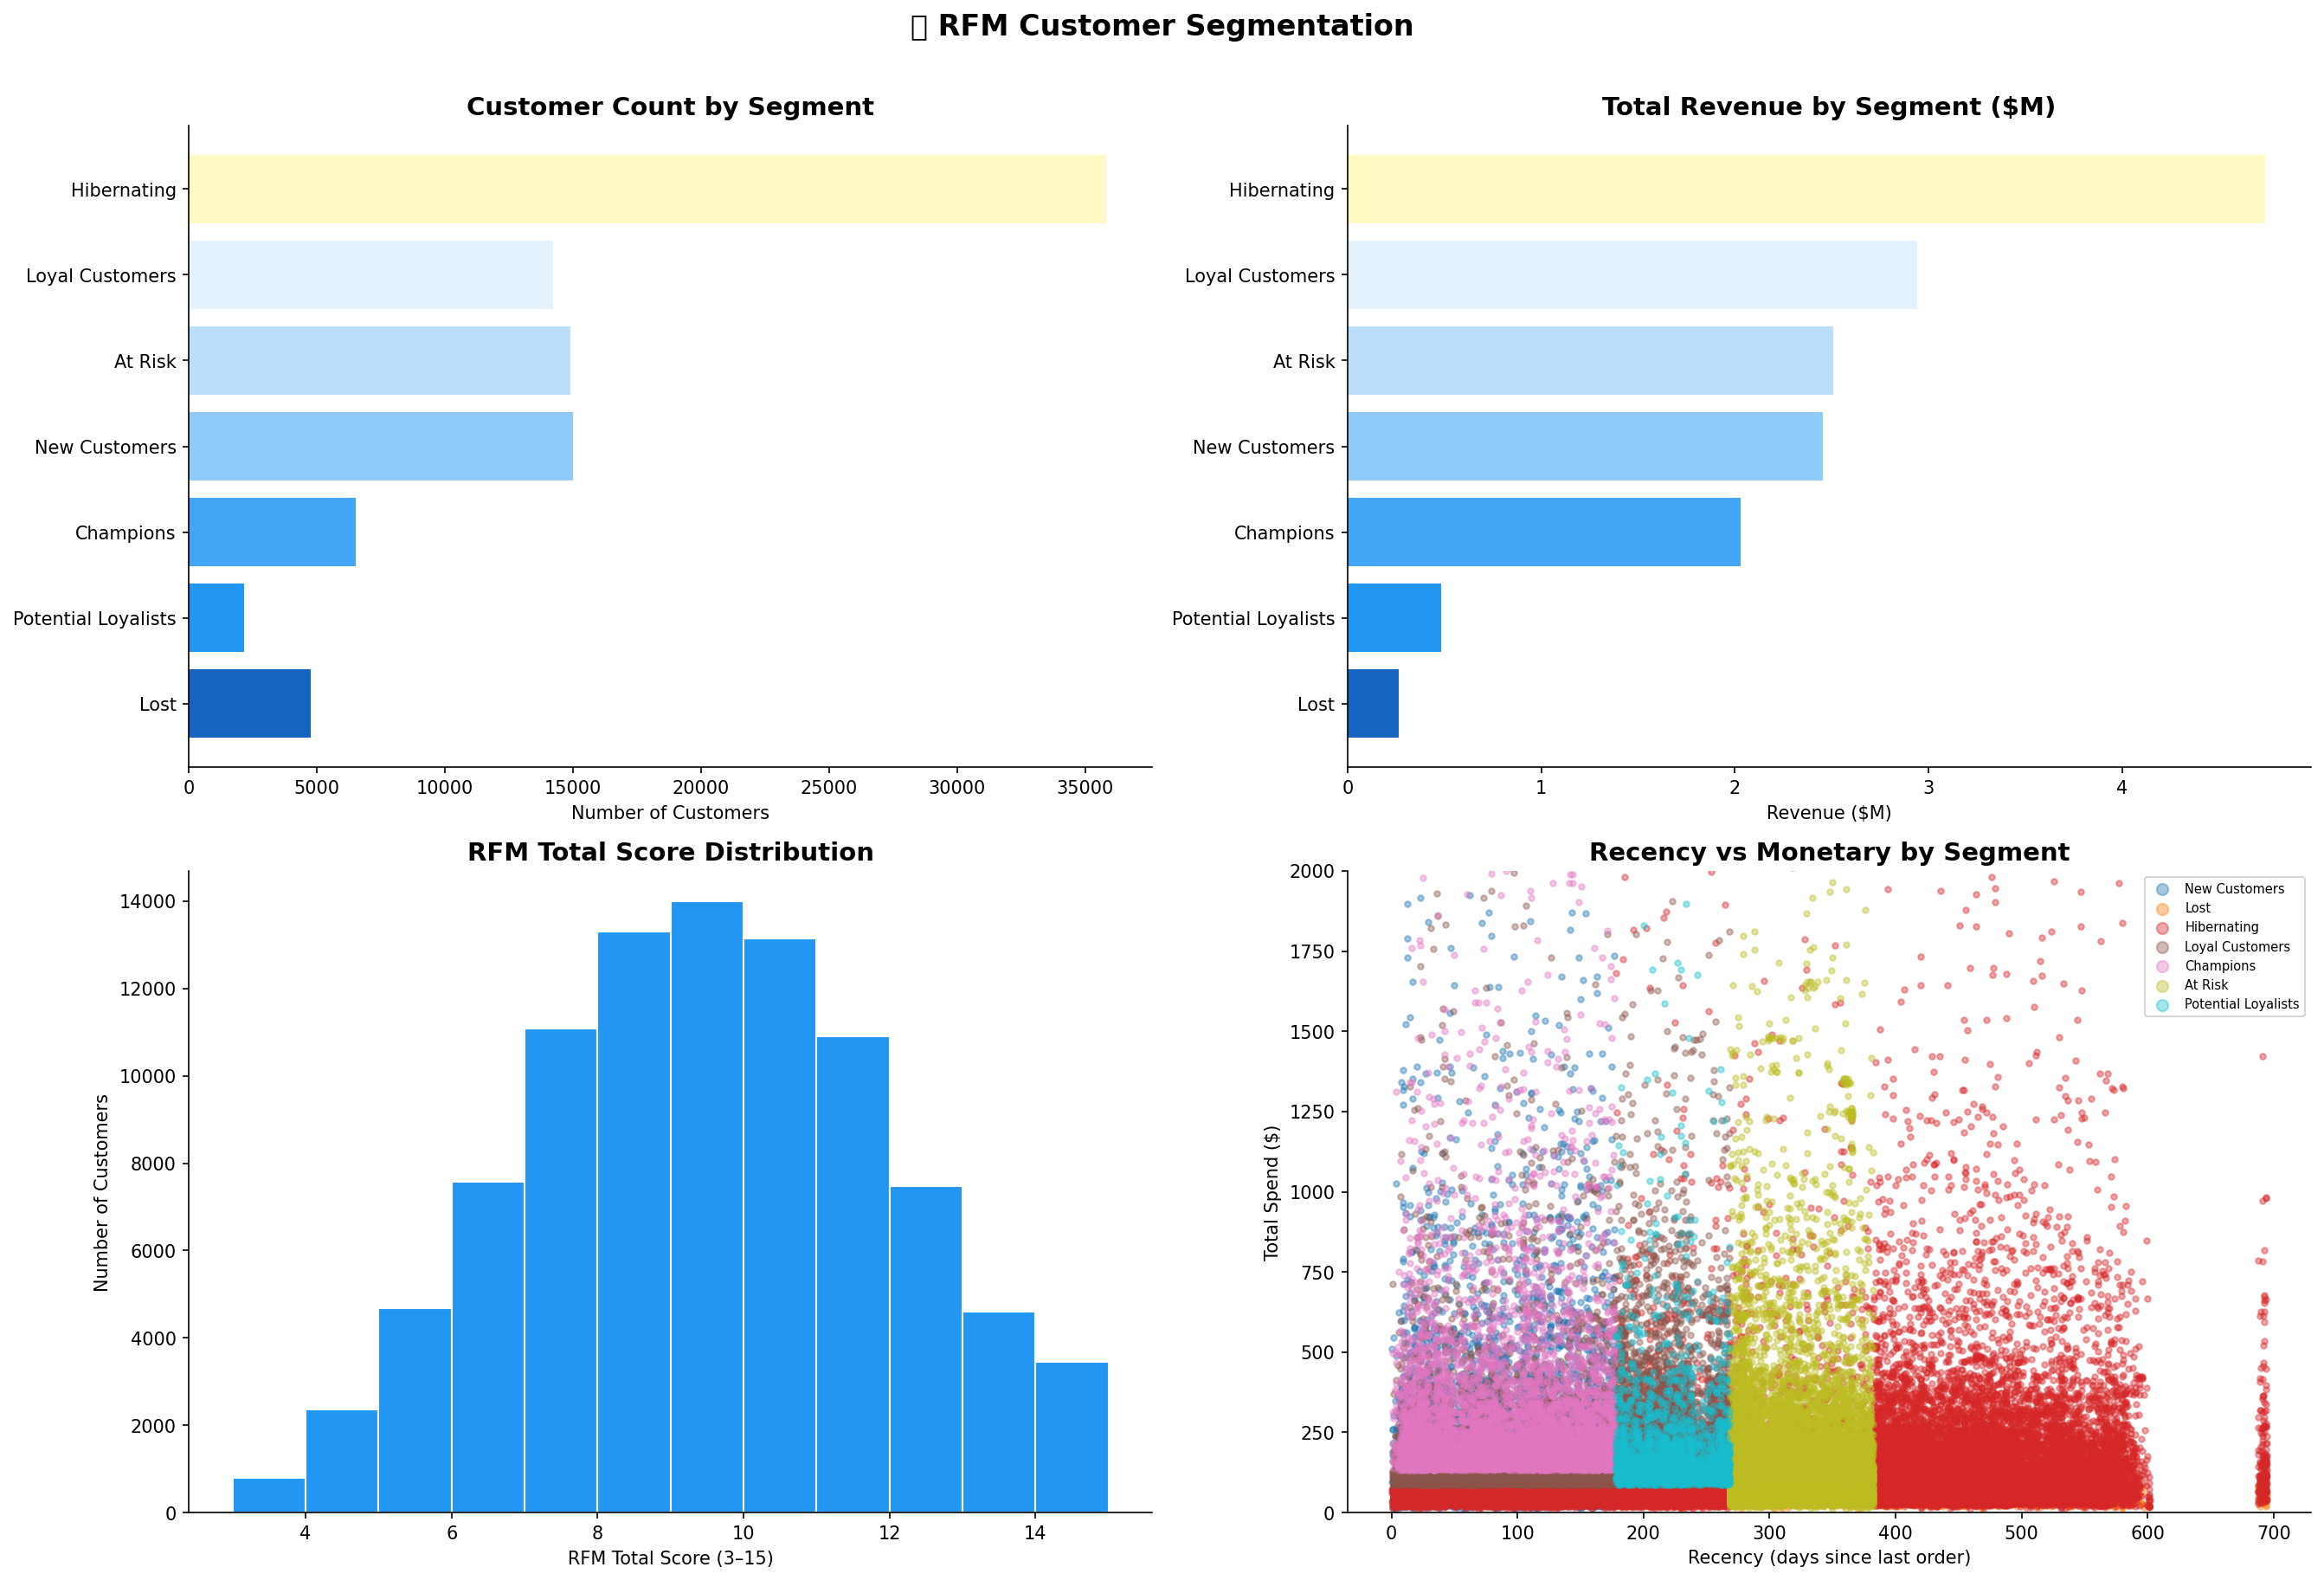


Segment Summary:
            segment  num_customers  avg_recency  avg_frequency  avg_monetary  total_revenue
        Hibernating          35832       303.20           1.02        132.24     4738473.30
    Loyal Customers          14227       153.20           1.05        206.88     2943332.45
            At Risk          14883       316.45           1.04        168.63     2509701.59
      New Customers          15006        90.81           1.00        163.49     2453385.54
          Champions           6504        91.07           1.18        312.25     2030887.71
Potential Loyalists           2155       221.46           1.00        224.00      482719.38
               Lost           4750       422.99           1.00         55.57      263961.80


In [4]:
seg_stats = (
    rfm.groupby("segment")
    .agg(
        num_customers = ("customer_id",   "count"),
        avg_recency   = ("recency_days",  "mean"),
        avg_frequency = ("frequency",     "mean"),
        avg_monetary  = ("monetary",      "mean"),
        total_revenue = ("monetary",      "sum"),
    )
    .round(2)
    .reset_index()
    .sort_values("total_revenue", ascending=False)
)

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1. Customer count per segment
colors = ["#1565C0","#2196F3","#42A5F5","#90CAF9","#BBDEFB","#E3F2FD","#FFF9C4"]
axes[0,0].barh(seg_stats["segment"][::-1],
               seg_stats["num_customers"][::-1], color=colors)
axes[0,0].set_title("Customer Count by Segment")
axes[0,0].set_xlabel("Number of Customers")

# 2. Revenue per segment
axes[0,1].barh(seg_stats["segment"][::-1],
               seg_stats["total_revenue"][::-1] / 1e6, color=colors)
axes[0,1].set_title("Total Revenue by Segment ($M)")
axes[0,1].set_xlabel("Revenue ($M)")

# 3. RFM score distribution
axes[1,0].hist(rfm["RFM_total"], bins=12,
               color="#2196F3", edgecolor="white")
axes[1,0].set_title("RFM Total Score Distribution")
axes[1,0].set_xlabel("RFM Total Score (3–15)")
axes[1,0].set_ylabel("Number of Customers")

# 4. Recency vs Monetary colored by segment
segment_list = rfm["segment"].unique()
palette = plt.cm.tab10(np.linspace(0, 1, len(segment_list)))
for seg, color in zip(segment_list, palette):
    mask = rfm["segment"] == seg
    axes[1,1].scatter(rfm[mask]["recency_days"],
                      rfm[mask]["monetary"],
                      label=seg, alpha=0.4, s=10, color=color)
axes[1,1].set_title("Recency vs Monetary by Segment")
axes[1,1].set_xlabel("Recency (days since last order)")
axes[1,1].set_ylabel("Total Spend ($)")
axes[1,1].legend(fontsize=7, markerscale=2)
axes[1,1].set_ylim(0, 2000)

plt.suptitle("👥 RFM Customer Segmentation", fontsize=16,
             fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(r"D:\customer_intelligence_platform\outputs\07_rfm_segmentation.png",
            bbox_inches="tight")
plt.show()

print("\nSegment Summary:")
print(seg_stats.to_string(index=False))

  K=2  inertia=330,318  silhouette=0.790
  K=3  inertia=210,577  silhouette=0.663
  K=4  inertia=149,638  silhouette=0.412
  K=5  inertia=122,779  silhouette=0.433
  K=6  inertia=98,116  silhouette=0.450
  K=7  inertia=84,520  silhouette=0.451
  K=8  inertia=71,343  silhouette=0.384
  K=9  inertia=62,647  silhouette=0.391


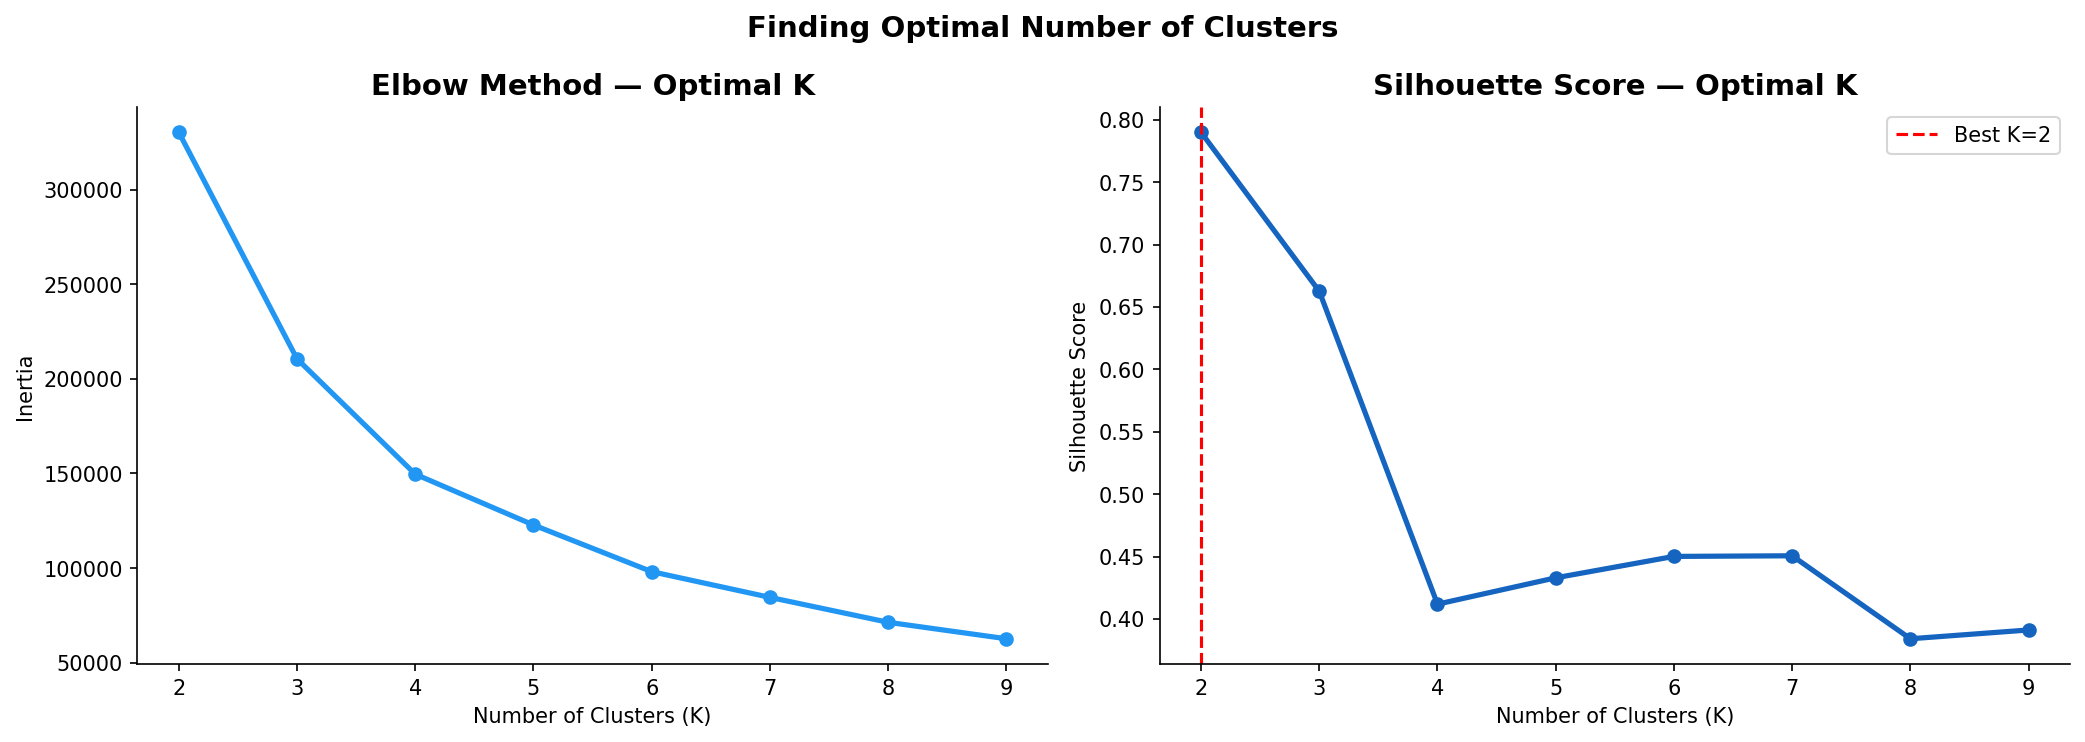


Best K = 2 (highest silhouette score)


In [5]:
# ── K-Means on RFM features ───────────────────────────────────────────────────
features = ["recency_days", "frequency", "monetary",
            "avg_order_value", "active_months"]

X = rfm[features].copy()

# Cap monetary outliers at 99th percentile
for col in ["monetary", "avg_order_value"]:
    cap = X[col].quantile(0.99)
    X[col] = X[col].clip(upper=cap)

# Scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ── Find optimal K with elbow + silhouette ────────────────────────────────────
inertias    = []
silhouettes = []
K_range     = range(2, 10)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_))
    print(f"  K={k}  inertia={km.inertia_:,.0f}  silhouette={silhouettes[-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(K_range), inertias, marker="o",
             color="#2196F3", linewidth=2.5)
axes[0].set_title("Elbow Method — Optimal K")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(K_range), silhouettes, marker="o",
             color="#1565C0", linewidth=2.5)
axes[1].set_title("Silhouette Score — Optimal K")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")

best_k = list(K_range)[silhouettes.index(max(silhouettes))]
axes[1].axvline(best_k, color="red", linestyle="--",
                label=f"Best K={best_k}")
axes[1].legend()

plt.suptitle("Finding Optimal Number of Clusters",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(r"D:\customer_intelligence_platform\outputs\08_optimal_k.png",
            bbox_inches="tight")
plt.show()

print(f"\nBest K = {best_k} (highest silhouette score)")

In [6]:
# ── Fit final model with best K ───────────────────────────────────────────────
FINAL_K = 4

km_final = KMeans(n_clusters=FINAL_K, random_state=42, n_init=10)
rfm["cluster"] = km_final.fit_predict(X_scaled)

# ── Profile each cluster ──────────────────────────────────────────────────────
cluster_profile = (
    rfm.groupby("cluster")
    .agg(
        num_customers = ("customer_id",   "count"),
        avg_recency   = ("recency_days",  "mean"),
        avg_frequency = ("frequency",     "mean"),
        avg_monetary  = ("monetary",      "mean"),
        avg_review    = ("avg_review",    "mean"),
        total_revenue = ("monetary",      "sum"),
    )
    .round(2)
    .reset_index()
    .sort_values("avg_monetary", ascending=False)
)

# ── Name clusters based on profile ───────────────────────────────────────────
def name_cluster(row):
    if row["avg_monetary"] > cluster_profile["avg_monetary"].quantile(0.75):
        return "High Value"
    elif row["avg_recency"] < cluster_profile["avg_recency"].quantile(0.25):
        return "Recent Active"
    elif row["avg_recency"] > cluster_profile["avg_recency"].quantile(0.75):
        return "Churned"
    else:
        return "Mid-Tier"

cluster_profile["cluster_name"] = cluster_profile.apply(name_cluster, axis=1)
rfm = rfm.merge(cluster_profile[["cluster","cluster_name"]], on="cluster", how="left")

print("Clusters fitted and named")
print("\nCluster Profiles:")
print(cluster_profile[["cluster_name","num_customers","avg_recency",
                        "avg_frequency","avg_monetary","total_revenue"]].to_string(index=False))

Clusters fitted and named

Cluster Profiles:
 cluster_name  num_customers  avg_recency  avg_frequency  avg_monetary  total_revenue
   High Value           4992       235.87           1.02        836.29     4174777.78
     Mid-Tier           1702       187.34           2.19        319.47      543746.31
      Churned          36835       387.99           1.01        123.64     4554170.53
Recent Active          49828       128.58           1.01        123.42     6149767.15


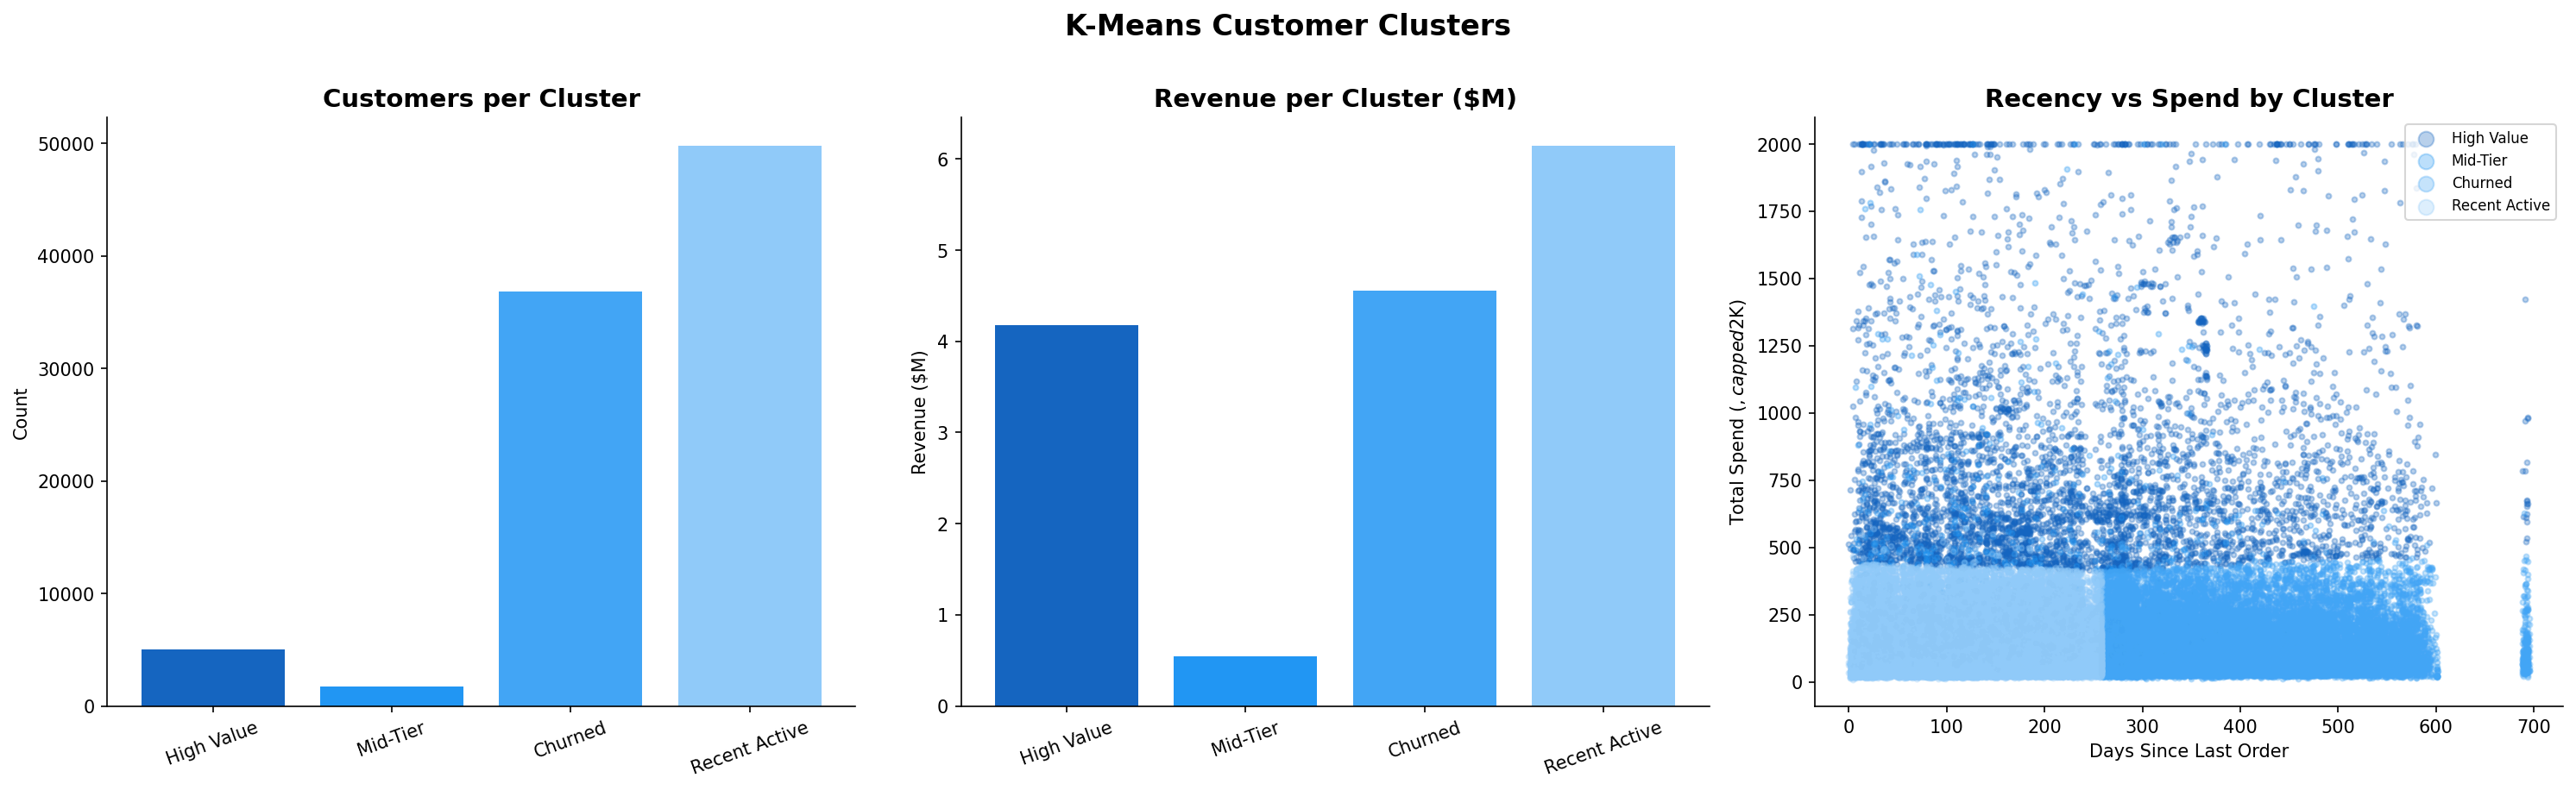


RFM table saved to database → table: rfm_segments

At-Risk + Lost customers  : 19,633
   Revenue at risk           : $2,773,663
   Avg spend (at-risk)       : $141


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

cluster_names = cluster_profile["cluster_name"].tolist()
colors = ["#1565C0","#2196F3","#42A5F5","#90CAF9","#BBDEFB"][:FINAL_K]

# 1. Customer count
axes[0].bar(cluster_profile["cluster_name"],
            cluster_profile["num_customers"], color=colors)
axes[0].set_title("Customers per Cluster")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=20)

# 2. Revenue per cluster
axes[1].bar(cluster_profile["cluster_name"],
            cluster_profile["total_revenue"] / 1e6, color=colors)
axes[1].set_title("Revenue per Cluster ($M)")
axes[1].set_ylabel("Revenue ($M)")
axes[1].tick_params(axis="x", rotation=20)

# 3. Scatter recency vs monetary
for cname, color in zip(cluster_names, colors):
    mask = rfm["cluster_name"] == cname
    axes[2].scatter(rfm[mask]["recency_days"],
                    rfm[mask]["monetary"].clip(upper=2000),
                    label=cname, alpha=0.3, s=8, color=color)
axes[2].set_title("Recency vs Spend by Cluster")
axes[2].set_xlabel("Days Since Last Order")
axes[2].set_ylabel("Total Spend ($, capped $2K)")
axes[2].legend(fontsize=8, markerscale=3)

plt.suptitle("K-Means Customer Clusters",
             fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(r"D:\customer_intelligence_platform\outputs\09_kmeans_clusters.png",
            bbox_inches="tight")
plt.show()

# ── Save RFM table to database ────────────────────────────────────────────────
from sqlalchemy import create_engine
engine2 = create_engine(f"sqlite:///{DB_PATH}")
rfm.to_sql("rfm_segments", con=engine2, if_exists="replace", index=False)
print("\nRFM table saved to database → table: rfm_segments")

# ── Business dollar impact ────────────────────────────────────────────────────
at_risk = rfm[rfm["segment"].isin(["At Risk", "Lost"])]
print(f"\nAt-Risk + Lost customers  : {len(at_risk):,}")
print(f"   Revenue at risk           : ${at_risk['monetary'].sum():,.0f}")
print(f"   Avg spend (at-risk)       : ${at_risk['monetary'].mean():,.0f}")